[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/23_vae.ipynb)

# 23 · Variational Autoencoders: Generating New Data From a Learned Latent Space

**Part 4 — Deep generative & representation learning** · Notebook 23 of 27

Classifiers answer "what is this?". A **generative model** answers a harder question: "what does data like this look like?", well enough to produce new examples that never existed. We met two simple generative models already: the Gaussian mixture (notebook 15), whose hidden variable is a discrete cluster label, and probabilistic PCA (notebook 16), whose hidden variable is a continuous vector mapped *linearly* to the data. Both generated blurry, unconvincing digits.

The **variational autoencoder** (VAE; Kingma & Welling, 2013) keeps PPCA's recipe (draw a hidden vector $z \sim \mathcal{N}(0, I)$, then generate $x$ from it) but replaces the linear map with a neural network. That makes the likelihood impossible to compute exactly, and the way around it combines three ideas we've built separately: the **ELBO** from EM (notebook 15), **neural networks** trained by backprop (notebooks 19–20), and one new trick, **reparameterization**, that lets gradients flow through random sampling. This is CX 4240 lecture 17's capstone of the probabilistic pipeline.

**What you'll learn**

1. From mixtures to deep latent variable models
2. Why maximum likelihood is now intractable
3. The plain autoencoder, and why it can't generate
4. The ELBO, again: an encoder that does approximate inference
5. The reparameterization trick
6. A VAE in PyTorch, trained on Fashion-MNIST
7. The latent space: a map of clothing
8. Generating, interpolating, and the role of the prior
9. The β knob: reconstruction vs. regularity
10. Limits (blur, posterior collapse) and what came next: VQ-VAE, GANs, diffusion

*Course map: CX 4240 lecture 17 (latent variable models: from GMMs to deep latent variable models, deep Gaussian LVMs, sampling as generation, intractable MLE, the ELBO, the autoencoder intuition, stochastic gradients and the reparameterization trick, VAE generation, GANs and diffusion) and lecture 18/21 (probabilistic PCA as an LVM; reconstruction and generation as pretext tasks for representation learning); ISYE 4600 W10 (autoencoders, the PCA connection, VAEs and GANs).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, gzip, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def load_fashion_mnist(root="data/fashion"):
    os.makedirs(root, exist_ok=True); out = {}
    for split, prefix in [("train", "train"), ("test", "t10k")]:
        for kind, offset in [("images", 16), ("labels", 8)]:
            fname = f"{prefix}-{kind}-idx{3 if kind == 'images' else 1}-ubyte.gz"; path = os.path.join(root, fname)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + fname, path)
            out[(split, kind)] = np.frombuffer(gzip.open(path).read(), np.uint8, offset=offset)
    return (out[("train", "images")].reshape(-1, 784), out[("train", "labels")], out[("test", "images")].reshape(-1, 784), out[("test", "labels")])

Xtr_np, ytr_np, Xte_np, yte_np = load_fashion_mnist()
N_TRAIN = 20000                                   # 60000 on a GPU runtime
Xtr = torch.tensor(Xtr_np[:N_TRAIN], dtype=torch.float32) / 255; ytr = ytr_np[:N_TRAIN]
Xte = torch.tensor(Xte_np, dtype=torch.float32) / 255
print(f"PyTorch on {device}; {len(Xtr):,} training images (pixels in [0, 1])")
print("Ready ✓")

Setup complete ✓


PyTorch on cpu; 20,000 training images (pixels in [0, 1])
Ready ✓


---
## 1. From mixtures to deep latent variable models

CX lecture 17 walks the path from the GMM. A **latent variable model** says each data point $x$ was produced from a hidden variable $z$:

$$p_\theta(x) = \int p(z)\,p_\theta(x \mid z)\,dz.$$

| Model | Hidden $z$ | How $x$ is generated from $z$ |
|---|---|---|
| GMM (notebook 15) | a cluster label, $K$ values | $\mathcal{N}(\mu_z, \Sigma_z)$: one Gaussian per label |
| Probabilistic PCA (notebook 16) | $z \sim \mathcal{N}(0, I_k)$ | $\mathcal{N}(Wz + \mu, \sigma^2 I)$: a **linear** map |
| **Deep latent variable model** | $z \sim \mathcal{N}(0, I_k)$ | $p_\theta(x \mid z)$ whose parameters are a **neural network** $f_\theta(z)$ |

Think of it as a GMM with **infinitely many components**, one for every point in a continuous latent space, whose centers lie on a curved surface traced out by the network (CX: *"GMMs: not flexible enough → infinite-many components: continuous z → make more flexible: deep models"*). **Sampling is generation**: draw $z$ from the prior, push it through the network.

For images with pixel values in [0, 1], a convenient $p_\theta(x \mid z)$ treats each pixel as a Bernoulli (or continuous Bernoulli) variable with mean given by the network's sigmoid output; its negative log-likelihood is the **binary cross-entropy** between the image and the network's output. With a Gaussian $p_\theta(x \mid z)$ it would be squared error instead.

---
## 2. Why maximum likelihood is now intractable

To fit $\theta$ by maximum likelihood we need $\log p_\theta(x) = \log\int p(z)p_\theta(x \mid z)\,dz$. For the GMM the integral was a sum of $K$ terms; for PPCA it had a closed form because everything was linear and Gaussian. With a neural network inside, there's no closed form.

The obvious numerical fix, Monte Carlo (draw many $z$ from the prior and average $p_\theta(x \mid z)$), fails in practice: for a specific image $x$, almost every random $z$ produces something completely different, with likelihood indistinguishable from zero. The few $z$ values that actually explain $x$ occupy a tiny region of latent space, and blind sampling almost never hits it. A small illustration in 2-D:

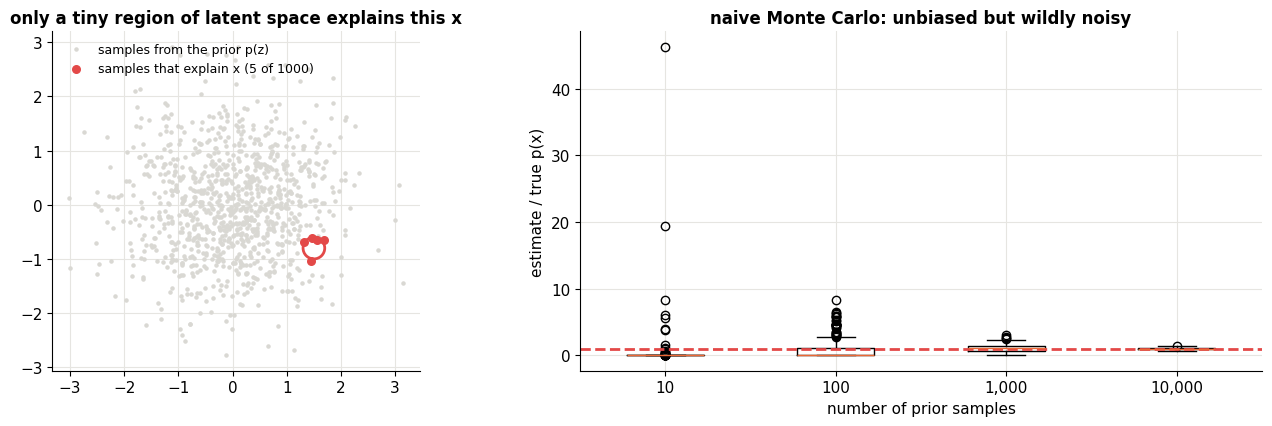

In [2]:
r_ = np.random.default_rng(0)
# A latent space where only a small region explains a given observation x: p(x|z) is a narrow bump around z* = (1.5, -0.8)
z_star, width = np.array([1.5, -0.8]), 0.08
lik = lambda Z: np.exp(-((Z - z_star) ** 2).sum(-1) / (2 * width ** 2))
true_px = 2 * np.pi * width ** 2 * np.exp(-(z_star ** 2).sum() / 2) / (2 * np.pi)    # exact ∫ N(z;0,I) lik(z) dz (small-width approximation)
estimates = {n: [lik(r_.normal(size=(n, 2))).mean() for _ in range(200)] for n in [10, 100, 1000, 10000]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
Z = r_.normal(size=(1000, 2)); hit = lik(Z) > 0.01
axes[0].scatter(*Z[~hit].T, s=5, color=C["light"], label="samples from the prior p(z)")
axes[0].scatter(*Z[hit].T, s=30, color=C["red"], label=f"samples that explain x ({hit.sum()} of 1000)")
axes[0].add_patch(plt.Circle(z_star, 2.5 * width, fill=False, color=C["red"], lw=2))
axes[0].set(aspect="equal", title="only a tiny region of latent space explains this x"); axes[0].legend(fontsize=9, loc="upper left")
axes[1].boxplot([np.array(v) / true_px for v in estimates.values()]); axes[1].set_xticks(range(1, len(estimates) + 1), [f"{n:,}" for n in estimates]); axes[1].axhline(1, color=C["red"], ls="--")
axes[1].set(xlabel="number of prior samples", ylabel="estimate / true p(x)", title="naive Monte Carlo: unbiased but wildly noisy")
fig.tight_layout(); plt.show()

With 10 samples the estimate is usually 0 (no sample landed in the red circle) and occasionally 20 to 40 times too big; even with 100 it routinely misses by a factor of several. In 2-D, thousands of samples eventually work; in a 16- or 100-dimensional latent space, the useful region is an exponentially smaller fraction of the prior, and blind sampling is hopeless.

The fix is to sample $z$ **where it matters**: from a distribution concentrated on the $z$'s that explain this particular $x$, i.e. the posterior $p_\theta(z \mid x)$. We can't compute that posterior either, but we can **learn an approximation** to it. That's the encoder.

---
## 3. The plain autoencoder, and why it can't generate

CX lecture 17 gives the intuition first: an **autoencoder** (ISYE W10). An **encoder** network compresses an image into a short code $z$, a **decoder** network reconstructs the image from the code, and both are trained to make the reconstruction match the input. With linear layers and squared error, the best autoencoder recovers exactly the PCA subspace (notebook 16). With nonlinear networks it can learn curved, much more compact representations. Let's train one with a **2-dimensional** code, so we can draw the code space:

autoencoder trained in 36s


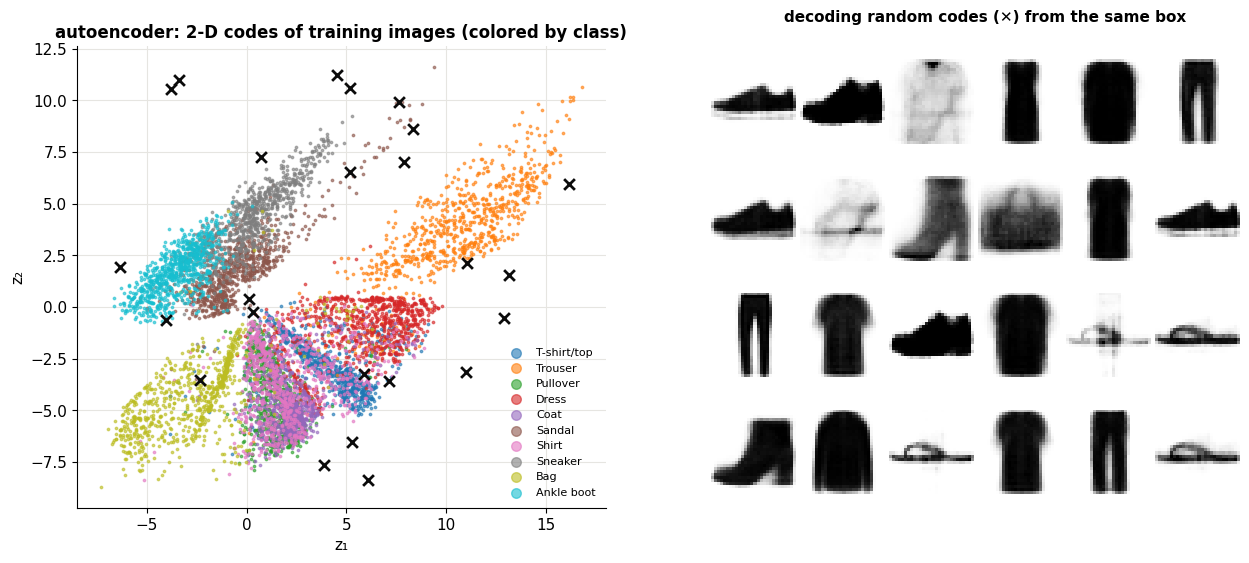

In [3]:
class Encoder(nn.Module):
    def __init__(self, z_dim, hidden=512, variational=True):
        super().__init__(); self.variational = variational
        self.body = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 256), nn.ReLU())
        self.mu = nn.Linear(256, z_dim); self.logvar = nn.Linear(256, z_dim) if variational else None
    def forward(self, x):
        h = self.body(x); return (self.mu(h), self.logvar(h)) if self.variational else self.mu(h)

class Decoder(nn.Module):
    def __init__(self, z_dim, hidden=512):
        super().__init__(); self.net = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(), nn.Linear(256, hidden), nn.ReLU(), nn.Linear(hidden, 784))
    def forward(self, z): return self.net(z)          # logits; sigmoid gives pixel means

def train_ae(z_dim=2, epochs=15, seed=0):
    torch.manual_seed(seed); enc, dec = Encoder(z_dim, variational=False).to(device), Decoder(z_dim).to(device)
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=1e-3)
    for ep in range(epochs):
        for idx in torch.randperm(len(Xtr)).split(128):
            x = Xtr[idx].to(device); loss = F.binary_cross_entropy_with_logits(dec(enc(x)), x, reduction="sum") / len(x)
            opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec

t0 = time.time(); ae_enc, ae_dec = train_ae(); print(f"autoencoder trained in {time.time() - t0:.0f}s")
with torch.no_grad(): Z_ae = ae_enc(Xtr.to(device)).cpu().numpy()

cmap10 = plt.get_cmap("tab10")
def plot_codes(ax, Z, title):
    for c in range(10):
        ax.scatter(*Z[ytr == c][:800].T, s=3, color=cmap10(c), label=CLASSES[c], alpha=0.6)
    ax.set(title=title, xlabel="z₁", ylabel="z₂")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_codes(axes[0], Z_ae, "autoencoder: 2-D codes of training images (colored by class)")
axes[0].legend(markerscale=4, fontsize=8, loc="best")
lo, hi = Z_ae.min(0), Z_ae.max(0)
rand_z = torch.tensor(np.random.default_rng(1).uniform(lo, hi, size=(24, 2)), dtype=torch.float32)
with torch.no_grad(): gen = torch.sigmoid(ae_dec(rand_z.to(device))).cpu().numpy()
axes[0].scatter(*rand_z.numpy().T, marker="x", s=60, color=C["ink"], label="random codes")
gs_ = axes[1].get_subplotspec().subgridspec(4, 6, wspace=0.05, hspace=0.05); axes[1].remove()
for k in range(24):
    a = fig.add_subplot(gs_[k // 6, k % 6]); a.imshow(gen[k].reshape(28, 28), cmap="gray_r"); a.axis("off")
fig.text(0.73, 0.92, "decoding random codes (✕) from the same box", ha="center", fontsize=11, weight="bold")
plt.show()

The autoencoder organizes the clothes nicely by class, with no labels involved. But as a *generator* it's unreliable: the codes occupy an irregular, stretched-out region with gaps and long arms, and nothing says what a code in a gap means. Decoding random points from the bounding box (✕) gives some plausible items, some smudges, and some hybrids from regions no training image ever mapped to. The autoencoder learned to **compress**, not to describe the *distribution* of codes. To generate, we need the codes to fill a known, simple region (say, a standard Gaussian) with no holes. That's what the VAE adds.

---
## 4. The ELBO, again

Here's the derivation from notebook 15, now with a continuous $z$. For one image $x$ and **any** distribution $q(z)$:

$$\log p_\theta(x) = \underbrace{\mathbb{E}_{q(z)}\big[\log p_\theta(x \mid z)\big] - \mathrm{KL}\big(q(z)\,\|\,p(z)\big)}_{\text{ELBO }\mathcal{L}(\theta, q;\,x)} + \mathrm{KL}\big(q(z)\,\|\,p_\theta(z \mid x)\big).$$

The last KL is never negative, so the ELBO is a lower bound on the log-likelihood, tight when $q$ equals the true posterior. In EM we set $q$ to the exact posterior in the E-step. Here the posterior is intractable, so instead we restrict $q$ to a simple family, a diagonal Gaussian, and let a neural network, the **encoder**, output its parameters for each $x$:

$$q_\phi(z \mid x) = \mathcal{N}\big(z;\; \mu_\phi(x),\; \mathrm{diag}\,\sigma^2_\phi(x)\big).$$

This is **amortized** inference: rather than solving an optimization for every image, one network learns to map any image to (an approximation of) its posterior. Then we maximize the ELBO over both networks at once, encoder $\phi$ and decoder $\theta$. Read the two terms as a loss (negated):

$$-\mathcal{L} = \underbrace{\mathbb{E}_{q_\phi(z \mid x)}\big[-\log p_\theta(x \mid z)\big]}_{\text{reconstruction error}} + \underbrace{\mathrm{KL}\big(q_\phi(z \mid x)\,\|\,\mathcal{N}(0, I)\big)}_{\text{keep codes near the prior}}.$$

- The **reconstruction** term is the autoencoder's loss, averaged over codes sampled from $q$: decode a *noisy* code and still reconstruct the image.
- The **KL** term pulls each image's code distribution toward the standard Gaussian prior. That's the regularizer that fills the holes: codes can't drift off into arbitrary corners, and they can't collapse to points, because shrinking $\sigma$ toward 0 costs KL.

For two Gaussians the KL has a closed form. With $q = \mathcal{N}(\mu, \mathrm{diag}\,\sigma^2)$ and $p = \mathcal{N}(0, I)$ in $k$ dimensions:

$$\mathrm{KL}(q\,\|\,p) = \frac12\sum_{j=1}^{k}\big(\mu_j^2 + \sigma_j^2 - \log\sigma_j^2 - 1\big).$$

Each coordinate pays for being off-center ($\mu_j^2$) and for having a variance different from 1. Let's check the formula against a Monte Carlo estimate:

In [4]:
mu_q, sig_q = np.array([1.0, -0.5, 0.2]), np.array([0.5, 1.2, 0.1])
kl_formula = 0.5 * (mu_q ** 2 + sig_q ** 2 - np.log(sig_q ** 2) - 1).sum()
zs = mu_q + sig_q * np.random.default_rng(0).normal(size=(400000, 3))
log_q = (-0.5 * ((zs - mu_q) / sig_q) ** 2 - np.log(sig_q) - 0.5 * np.log(2 * np.pi)).sum(1)
log_p = (-0.5 * zs ** 2 - 0.5 * np.log(2 * np.pi)).sum(1)
print(f"KL closed form: {kl_formula:.4f}    Monte Carlo E_q[log q − log p]: {(log_q - log_p).mean():.4f}")

KL closed form: 2.8084    Monte Carlo E_q[log q − log p]: 2.8067


---
## 5. The reparameterization trick

There's one obstacle. The reconstruction term is an expectation over $z \sim q_\phi(z \mid x)$, and we need its gradient with respect to $\phi$, the encoder's weights. But sampling is not a differentiable operation: if the code is "a random draw from $\mathcal{N}(\mu, \sigma^2)$", how does the loss change when $\mu$ changes slightly?

The **reparameterization trick** (CX lecture 17) moves the randomness out of the way. Draw standard noise $\varepsilon \sim \mathcal{N}(0, I)$, which doesn't depend on $\phi$, and compute

$$z = \mu_\phi(x) + \sigma_\phi(x) \odot \varepsilon.$$

This $z$ has exactly the distribution $\mathcal{N}(\mu, \sigma^2)$, but now it's a **deterministic, differentiable** function of $\mu$ and $\sigma$ (with $\varepsilon$ as an extra input), so backprop flows straight through it: $\partial z/\partial\mu = 1$, $\partial z/\partial\sigma = \varepsilon$.

The alternative, the score-function (REINFORCE) estimator, works for any distribution but has much higher variance. A tiny comparison: estimate $\frac{d}{d\mu}\mathbb{E}_{z\sim\mathcal{N}(\mu, 1)}[z^2]$, whose true value is $2\mu$:

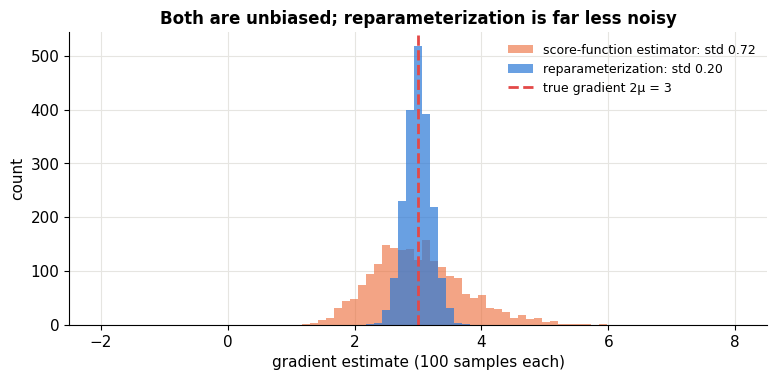

In [5]:
mu0, n = 1.5, 100
r_ = np.random.default_rng(0)
reparam, score = [], []
for _ in range(2000):
    eps = r_.normal(size=n); z = mu0 + eps
    reparam.append((2 * z * 1.0).mean())                    # d/dμ f(μ + ε) = f′(z)·1
    score.append((z ** 2 * (z - mu0)).mean())               # f(z) · d/dμ log N(z; μ, 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(-2, 8, 80)
ax.hist(score, bins=bins, alpha=0.6, color=C["orange"], label=f"score-function estimator: std {np.std(score):.2f}")
ax.hist(reparam, bins=bins, alpha=0.7, color=C["blue"], label=f"reparameterization: std {np.std(reparam):.2f}")
ax.axvline(2 * mu0, color=C["red"], ls="--", label="true gradient 2μ = 3")
ax.set(xlabel="gradient estimate (100 samples each)", ylabel="count", title="Both are unbiased; reparameterization is far less noisy"); ax.legend(fontsize=9); plt.show()

Both estimators average to the right answer, but the reparameterized one is several times less noisy, which is what makes VAE training with a single sample per image practical. (Score-function estimators come back in notebook 26: the policy-gradient methods of reinforcement learning use them because the "sampling" there, choosing words, is discrete.)

---
## 6. A VAE in PyTorch

Putting it together: the encoder outputs $\mu$ and $\log\sigma^2$ (predicting the log keeps $\sigma^2$ positive), we sample $z$ by reparameterization, decode, and minimize reconstruction + KL:

In [6]:
class VAE(nn.Module):
    def __init__(self, z_dim=2):
        super().__init__(); self.enc, self.dec, self.z_dim = Encoder(z_dim), Decoder(z_dim), z_dim
    def forward(self, x):
        mu, logvar = self.enc(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)          # reparameterization trick
        return self.dec(z), mu, logvar

def vae_loss(logits, x, mu, logvar, beta=1.0):
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)   # −E_q[log p(x|z)], one sample
    kl = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum() / len(x)                  # closed-form KL to N(0, I)
    return recon + beta * kl, recon, kl

def train_vae(z_dim=2, epochs=15, beta=1.0, seed=0, verbose=False):
    torch.manual_seed(seed); model = VAE(z_dim).to(device); opt = torch.optim.Adam(model.parameters(), lr=1e-3); hist = []
    for ep in range(epochs):
        tot = np.zeros(3); n = 0
        for idx in torch.randperm(len(Xtr)).split(128):
            x = Xtr[idx].to(device); logits, mu, logvar = model(x)
            loss, rec, kl = vae_loss(logits, x, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += np.array([loss.item(), rec.item(), kl.item()]) * len(x); n += len(x)
        hist.append(tot / n)
        if verbose: print(f"epoch {ep + 1:2d}: −ELBO {tot[0] / n:6.1f} = reconstruction {tot[1] / n:6.1f} + KL {tot[2] / n:5.2f}  (nats per image)")
    return model, np.array(hist)

t0 = time.time(); vae2, h2 = train_vae(z_dim=2, verbose=True); print(f"trained in {time.time() - t0:.0f}s")

epoch  1: −ELBO  315.5 = reconstruction  309.4 + KL  6.14  (nats per image)


epoch  2: −ELBO  275.6 = reconstruction  269.1 + KL  6.56  (nats per image)


epoch  3: −ELBO  270.6 = reconstruction  264.3 + KL  6.30  (nats per image)


epoch  4: −ELBO  268.4 = reconstruction  262.1 + KL  6.22  (nats per image)


epoch  5: −ELBO  266.3 = reconstruction  260.1 + KL  6.22  (nats per image)


...

epoch 11: −ELBO  261.4 = reconstruction  255.2 + KL  6.26  (nats per image)


epoch 12: −ELBO  261.1 = reconstruction  254.8 + KL  6.27  (nats per image)


epoch 13: −ELBO  260.6 = reconstruction  254.3 + KL  6.29  (nats per image)


epoch 14: −ELBO  260.4 = reconstruction  254.1 + KL  6.28  (nats per image)


epoch 15: −ELBO  259.9 = reconstruction  253.6 + KL  6.28  (nats per image)
trained in 39s


The loss is measured in nats per image: the KL term is the "cost" (in information) of each image's code, and with 2 latent dimensions the model can only afford a few nats, so the reconstruction term dominates. Let's look at what it learned.

---
## 7. The latent space: a map of clothing

Encode every training image to its mean code $\mu_\phi(x)$, and, separately, decode a regular grid of codes spanning the prior's typical range. The grid of decoded images is the **learned manifold**: the curved 2-D surface of images the decoder can produce.

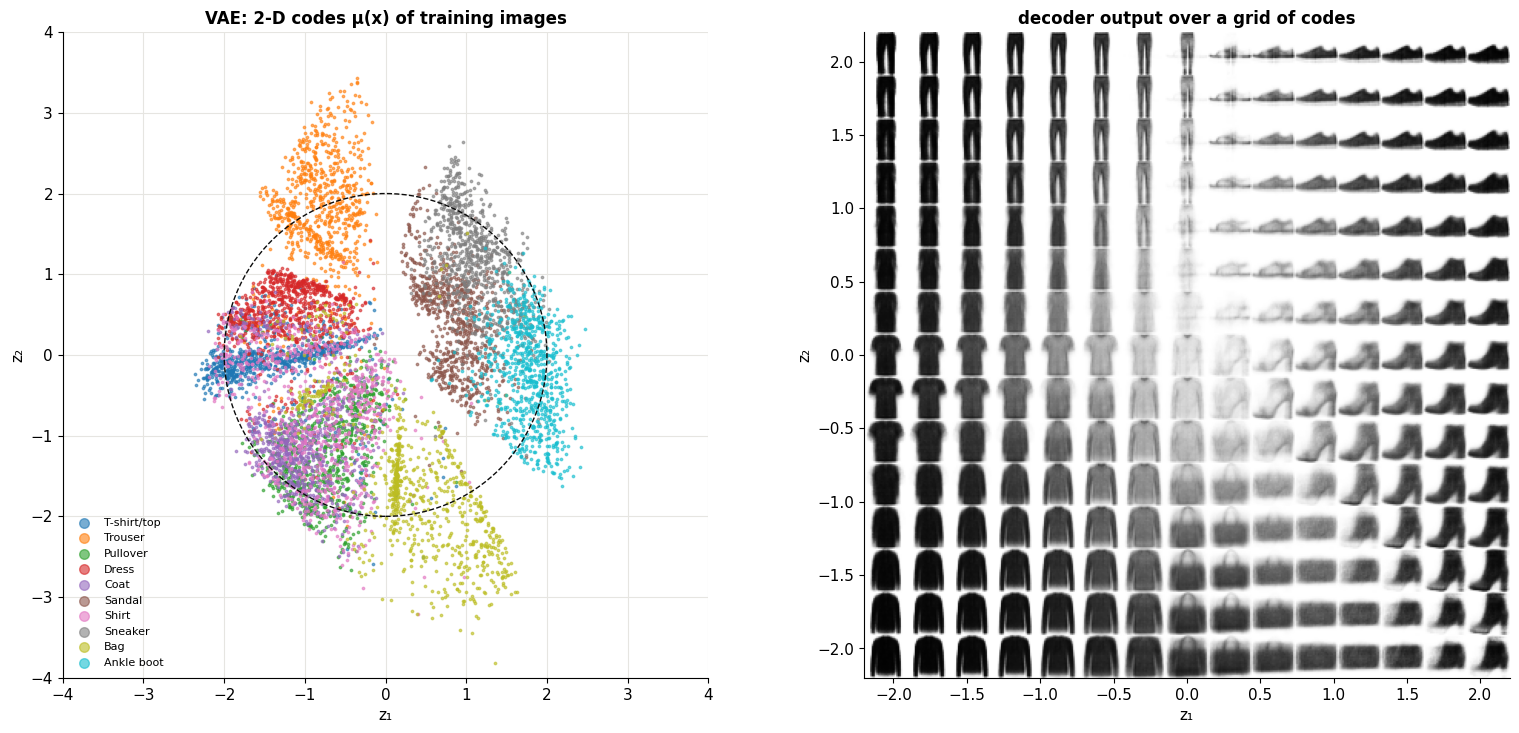

In [7]:
vae2.eval()
with torch.no_grad():
    mu_all = vae2.enc(Xtr.to(device))[0].cpu().numpy()
    grid_n = 15; g = np.linspace(-2.2, 2.2, grid_n)                       # ±2.2 covers most of N(0, 1)
    zz = torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32)
    tiles = torch.sigmoid(vae2.dec(zz.to(device))).cpu().numpy().reshape(grid_n, grid_n, 28, 28)
canvas = np.block([[tiles[i, j] for j in range(grid_n)] for i in range(grid_n)])
fig, axes = plt.subplots(1, 2, figsize=(16, 7.4))
plot_codes(axes[0], mu_all, "VAE: 2-D codes μ(x) of training images")
axes[0].add_patch(plt.Circle((0, 0), 2, fill=False, ls="--", color=C["ink"])); axes[0].set(aspect="equal", xlim=(-4, 4), ylim=(-4, 4))
axes[0].legend(markerscale=4, fontsize=8, loc="lower left")
axes[1].imshow(canvas, cmap="gray_r", extent=(-2.2, 2.2, -2.2, 2.2)); axes[1].set(title="decoder output over a grid of codes", xlabel="z₁", ylabel="z₂"); axes[1].grid(False)
fig.tight_layout(); plt.show()

Compare with the autoencoder: the VAE's codes form a compact, roughly circular cloud centered at the origin (the dashed circle is radius 2 under the prior), with classes arranged as neighboring regions and **no empty gaps**. The decoded grid on the right is a smooth map of clothing: footwear in one area, morphing from sandals to sneakers to boots; trousers in another; tops and coats blending into each other. Every point decodes to something plausible, because the KL term forced the training codes to cover the prior and the reconstruction term made each region decode to its neighbors' images. (The classes that people confuse, shirts, pullovers, coats, overlap here too.)

---
## 8. Generating, interpolating, and the role of the prior

**Generation** is now honest sampling from the model: $z \sim \mathcal{N}(0, I)$, then decode. A 2-D code is a tight bottleneck, so let's also train a VAE with a 16-dimensional latent space and compare samples:

16-D VAE trained in 47s; final −ELBO 241.4 (2-D: 259.9) nats per image


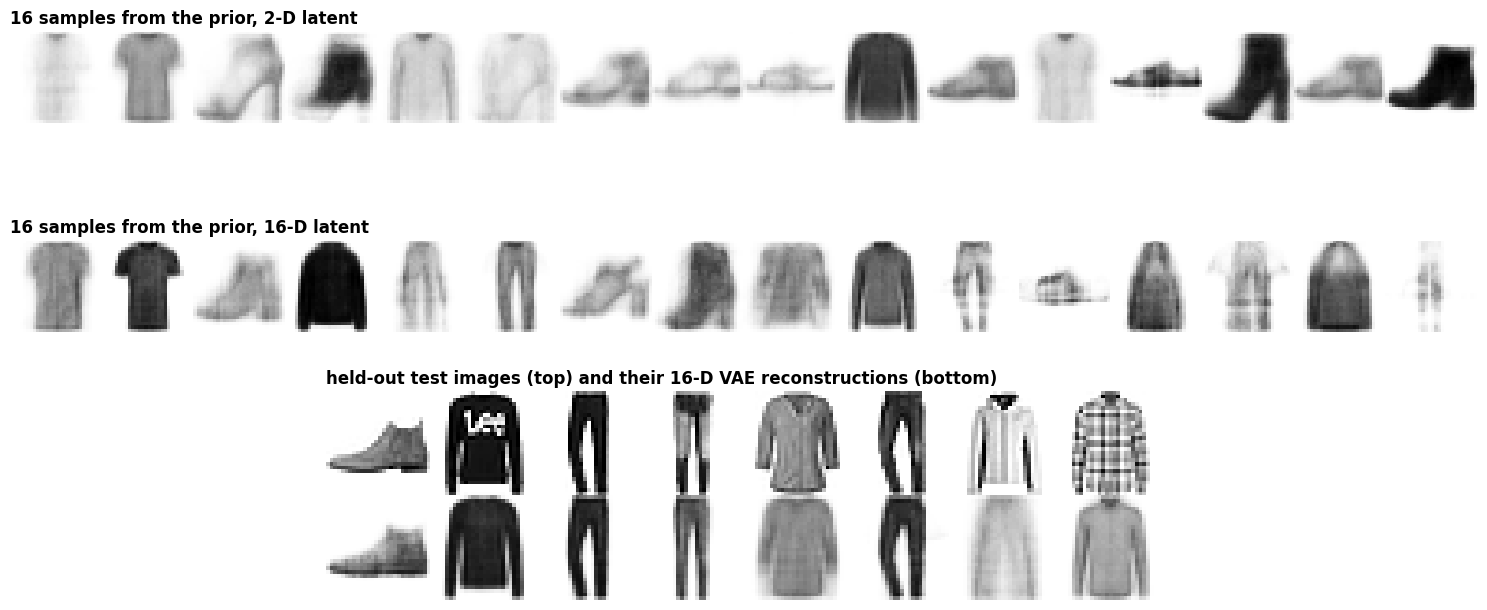

In [8]:
t0 = time.time(); vae16, h16 = train_vae(z_dim=16, epochs=20); print(f"16-D VAE trained in {time.time() - t0:.0f}s; final −ELBO {h16[-1, 0]:.1f} (2-D: {h2[-1, 0]:.1f}) nats per image")
vae16.eval()
fig, axes = plt.subplots(3, 1, figsize=(15, 6.6))
with torch.no_grad():
    for ax, (m, nm) in zip(axes[:2], [(vae2, "2-D latent"), (vae16, "16-D latent")]):
        s = torch.sigmoid(m.dec(torch.randn(16, m.z_dim, generator=torch.Generator().manual_seed(3)).to(device))).cpu().numpy()
        ax.imshow(np.hstack([im.reshape(28, 28) for im in s]), cmap="gray_r"); ax.set_title(f"16 samples from the prior, {nm}", loc="left"); ax.axis("off")
    recon = torch.sigmoid(vae16(Xte[:8].to(device))[0]).cpu().numpy()
    axes[2].imshow(np.hstack([np.vstack([Xte[i].numpy().reshape(28, 28), recon[i].reshape(28, 28)]) for i in range(8)]), cmap="gray_r")
    axes[2].set_title("held-out test images (top) and their 16-D VAE reconstructions (bottom)", loc="left"); axes[2].axis("off")
fig.tight_layout(); plt.show()

The 16-D model reconstructs much more detail and its samples are more varied, though both are noticeably **blurry**: section 10 explains why.

**Interpolation.** Because the latent space is smooth, walking in a straight line between two images' codes decodes to a gradual morph. 🎚️ **Pick two test images and move between them:**

In [9]:
with torch.no_grad(): mu_te16 = vae16.enc(Xte[:200].to(device))[0]
def interpolate(a=0, b=1, t=0.5):
    with torch.no_grad():
        ts = torch.linspace(0, 1, 9); zs = (1 - ts[:, None]) * mu_te16[a] + ts[:, None] * mu_te16[b]
        strip = torch.sigmoid(vae16.dec(zs)).cpu().numpy(); cur = torch.sigmoid(vae16.dec(((1 - t) * mu_te16[a] + t * mu_te16[b])[None]))[0].cpu().numpy()
    fig = plt.figure(figsize=(15, 3.4)); gs_ = fig.add_gridspec(1, 12, wspace=0.08)
    ax = fig.add_subplot(gs_[0, 0]); ax.imshow(Xte[a].reshape(28, 28), cmap="gray_r"); ax.set_title(f"A: {CLASSES[yte_np[a]]}", fontsize=9); ax.axis("off")
    for k in range(9):
        ax = fig.add_subplot(gs_[0, 1 + k]); ax.imshow(strip[k].reshape(28, 28), cmap="gray_r"); ax.axis("off"); ax.set_title(f"t={k / 8:.2f}", fontsize=8)
    ax = fig.add_subplot(gs_[0, 10]); ax.imshow(Xte[b].reshape(28, 28), cmap="gray_r"); ax.set_title(f"B: {CLASSES[yte_np[b]]}", fontsize=9); ax.axis("off")
    ax = fig.add_subplot(gs_[0, 11]); ax.imshow(cur.reshape(28, 28), cmap="magma"); ax.set_title(f"t = {t:.2f}", fontsize=9); ax.axis("off")
    plt.show()

interact(interpolate, a=IntSlider(value=0, min=0, max=199, description="image A"), b=IntSlider(value=1, min=0, max=199, description="image B"),
         t=FloatSlider(value=0.5, min=0, max=1, step=0.05, description="t"));

Ankle boot to trouser, shirt to sneaker: the intermediate images are plausible blends rather than a cross-fade of pixels, because the path stays inside the region of latent space the decoder was trained on.

> 🤔 **Question: Why does the VAE need the prior at all? Couldn't we just add noise to an autoencoder's codes?**
>
> Adding noise to codes (without the KL term) is partway there, but the encoder can defeat it by spreading the codes far apart, so the noise becomes relatively tiny and the gaps between classes stay. The KL term pins the overall scale: codes must stay near the origin *and* keep variance near 1, so the noise is meaningful and the codes must share space. The prior also gives us the sampling distribution for generation for free. In practice, a VAE's *aggregate* code distribution (all the images' $q(z \mid x)$ pooled) doesn't match the prior exactly, which is one reason samples are worse than reconstructions.

---
## 9. The β knob

The two terms of the loss pull in opposite directions: reconstruction wants informative, precise codes; the KL wants codes that look like the prior (uninformative). Multiplying the KL by a weight $\beta$ (the **β-VAE**; Higgins et al., 2017) makes the trade-off explicit. 🎚️ **Compare β values:**

In [10]:
betas = [0.1, 1.0, 4.0, 16.0]
beta_models = {b: train_vae(z_dim=2, epochs=12, beta=b, seed=0) for b in betas}
def beta_demo(beta_index=1):
    b = betas[beta_index]; m, h = beta_models[b]; m.eval()
    with torch.no_grad():
        mu = m.enc(Xtr[:4000].to(device))[0].cpu().numpy()
        rec = torch.sigmoid(m(Xte[:8].to(device))[0]).cpu().numpy()
        samp = torch.sigmoid(m.dec(torch.randn(8, 2, generator=torch.Generator().manual_seed(0)).to(device))).cpu().numpy()
    fig = plt.figure(figsize=(16, 5)); gs_ = fig.add_gridspec(3, 9, width_ratios=[3] + [1] * 8, wspace=0.05)
    ax = fig.add_subplot(gs_[:, 0])
    for c in range(10): ax.scatter(*mu[ytr[:4000] == c].T, s=3, color=cmap10(c))
    ax.add_patch(plt.Circle((0, 0), 2, fill=False, ls="--")); ax.set(aspect="equal", xlim=(-5, 5), ylim=(-5, 5), title=f"β = {b}: codes μ(x)")
    for k in range(8):
        for row, imgs in enumerate([Xte[:8].numpy(), rec, samp]):
            a_ = fig.add_subplot(gs_[row, 1 + k]); a_.imshow(imgs[k].reshape(28, 28), cmap="gray_r"); a_.axis("off")
    fig.text(0.62, 0.93, f"rows: test images · reconstructions (error {h[-1, 1]:.0f} nats) · samples from the prior (KL {h[-1, 2]:.2f} nats)", ha="center", fontsize=10)
    plt.show()

interact(beta_demo, beta_index=IntSlider(value=1, min=0, max=len(betas) - 1, description="β 0.1…16", readout=False));

- **Small β (0.1)**: nearly an autoencoder. Sharper reconstructions, but the codes spread far beyond the prior's circle, so samples drawn from the prior land in poorly covered regions.
- **β = 1**: the true ELBO, a balance.
- **Large β (4, 16)**: the KL penalty dominates. Codes squeeze toward the origin and overlap; the model stores less information per image, and reconstructions become generic blurry prototypes (at very high β, close to the average item of a few classes). β-VAEs with β > 1 are used to encourage **disentangled** latent dimensions, at the cost of reconstruction quality.

---
## 10. Limits, and what came next

**Blur.** VAE samples are blurrier than real images. Part of the reason is the pixelwise likelihood: if the decoder is unsure whether an edge belongs one pixel left or right, the loss-minimizing output is the **average**, a soft edge. Another part is the simple Gaussian $q$: the true posterior can't be represented exactly, so the bound is loose.

**Posterior collapse.** With a very powerful decoder (for example, an autoregressive one that can model the image pixel by pixel), the model can ignore $z$ entirely: set $q(z \mid x) = p(z)$ (KL = 0) and let the decoder do all the work. Remedies include KL annealing (start with β near 0), "free bits", and weaker decoders.

**What came next** (CX lecture 17: *"Beyond VAE: GAN, diffusion models"*):

| Model | Idea | Trained by |
|---|---|---|
| **VQ-VAE** (2017) | discrete codes from a learned codebook (k-means in latent space, notebook 14) | reconstruction + codebook losses; the codes become "image tokens" for transformers |
| **GAN** (2014) | a generator vs. a discriminator that tries to tell real from fake (ISYE W10: *"trained by competition, not likelihood maximization"*) | a minimax game; sharp samples, unstable training, no encoder |
| **Normalizing flows** | invertible networks, so $p(x)$ is exact by change of variables | exact maximum likelihood |
| **Diffusion models** (2020–) | learn to undo a gradual noising process, step by step | a weighted **ELBO** over many latent steps: a very deep, fixed-encoder VAE |

Diffusion models, the engine behind today's image generators, are trained with a variational bound of exactly the type derived here, with the "encoder" fixed to adding Gaussian noise and the decoder a network that denoises.

---
## 11. Summary

- A **deep latent variable model** generates $x$ by drawing $z \sim \mathcal{N}(0, I)$ and decoding it with a neural network: a GMM with infinitely many components, or a nonlinear PPCA.
- Its likelihood $\int p(z)p_\theta(x \mid z)dz$ is intractable, and naive Monte Carlo is hopeless because few $z$ explain any given $x$.
- The **VAE** maximizes the **ELBO** $= \mathbb{E}_q[\log p_\theta(x \mid z)] - \mathrm{KL}(q_\phi(z \mid x)\,\|\,p(z))$, with an **encoder** network giving an approximate posterior for every $x$ (amortized inference).
- The **reparameterization trick** $z = \mu + \sigma\odot\varepsilon$ makes the sampling step differentiable, giving low-variance gradients.
- The KL term turns an autoencoder's irregular code space into a smooth, hole-free one that matches the prior, which is what makes **generation** and **interpolation** work. **β** trades reconstruction for regularity.
- The same variational idea underlies diffusion models; contrastive learning (next notebook) takes a different route to good representations, without generating anything.

### ✏️ Exercises

1. Derive the closed-form KL between $\mathcal{N}(\mu, \sigma^2)$ and $\mathcal{N}(0, 1)$ in one dimension, then extend to diagonal covariance in $k$ dimensions.
2. Show that a VAE with a linear decoder $p_\theta(x \mid z) = \mathcal{N}(Wz + b, \sigma^2 I)$ and Gaussian encoder can represent probabilistic PCA exactly (CX lecture 18). Train one on the digits from notebook 16 and compare its decoder's column space with the top PCA directions.
3. Estimate the true $\log p_\theta(x)$ for a few test images with **importance sampling**: draw $z^{(s)} \sim q_\phi(z \mid x)$ and average $p(z^{(s)})p_\theta(x \mid z^{(s)})/q_\phi(z^{(s)} \mid x)$. How much larger than the ELBO is it?
4. Replace the MLP encoder and decoder with convolutional ones (notebook 21) and compare samples at 16 latent dimensions.
5. Make it a **conditional VAE**: feed the class label (one-hot) to both encoder and decoder, then generate 10 samples of each class on demand.
6. Train a VAE with KL annealing (β rising linearly from 0 to 1 over the first 5 epochs) and compare the final ELBO and the number of "active" latent dimensions (those whose average KL exceeds 0.01 nats).

### References

- CX 4240 lecture 17 (Latent Variable Model: Variational Auto-Encoder) and lectures 18, 21; ISYE 4600 W10.
- D. Kingma & M. Welling, *Auto-Encoding Variational Bayes*, ICLR (2014); D. Rezende, S. Mohamed & D. Wierstra, *Stochastic Backpropagation and Approximate Inference in Deep Generative Models*, ICML (2014).
- C. Doersch, *Tutorial on Variational Autoencoders* (2016); D. Kingma & M. Welling, *An Introduction to Variational Autoencoders*, Foundations and Trends in ML (2019).
- I. Higgins et al., *β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework*, ICLR (2017).
- A. van den Oord, O. Vinyals & K. Kavukcuoglu, *Neural Discrete Representation Learning* (VQ-VAE), NeurIPS (2017).
- I. Goodfellow et al., *Generative Adversarial Nets*, NeurIPS (2014); J. Ho, A. Jain & P. Abbeel, *Denoising Diffusion Probabilistic Models*, NeurIPS (2020).

**Next → [24 · Contrastive Learning](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/24_contrastive_learning.ipynb)**